# XRO from the observed state and from the E3SM state (1 Nov 2026 start)

The same XRO (control setup of `enso/07_xro_events`, trained on the observed 1981-2025 state vector) run
from two initial states:

* **XRO(obs):** the latest fully observed state (printed below). The observed state vector (HadISST 1.1 SST,
  EN4.2.2 OHC700) is complete through **Sep 2026** at the time of writing: both products reach Oct in early
  December, so this run starts two months before the E3SM start; its Nov 2026 state is shown for a
  like-for-like comparison. (`xc.obs_state` rebuilds itself when the archive files are extended.)
* **XRO(E3SM):** each of the 30 pooled E3SM members' Nov 2026 state (lead 0 of the 1 Nov 2026 runs,
  drift-corrected anomalies from 1981-2010, detrended with the XRO trend), run for 36 months.

Both are compared with E3SM's own forecast (the 30 members, `start_drift` held after lead 23, as in the other
diagnostics) and the observations so far. This separates the two causes of a difference between E3SM and an
observation-based XRO forecast:

* **initial state:** XRO(E3SM) vs XRO(obs), same dynamics, different start;
* **dynamics:** E3SM vs XRO(E3SM), same start, different model.

All anomalies are from 1981-2010 with the XRO trend added back, so XRO and E3SM share the reference of the
fixed 1981-2010 drift correction (the base-period question is in `01`-`03`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from util import xro_case as xc

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/09_xro_obs_vs_e3sm_init"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/09_xro_obs_vs_e3sm_init/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"
CLIM_METHOD = "start_drift"                 # E3SM drift correction (hindcast_state)

YEAR, INIT = 2026, 11
NLEAD = rc.start_nlead(YEAR, INIT)          # 36: Nov 2026 - Oct 2029
END = xc.add_months(YEAR, INIT, NLEAD - 1)  # last target month (2029, 10)
TRAIN = xc.EVENTS[YEAR]["train"]            # XRO training years (1981-2025)
SETUP = xc.XRO_SETUP
NCOPY_E3SM = 10                             # stochastic XRO copies per E3SM member (30 x 10)
LO, HI = SETUP["spread"]
THRESHOLD = -0.5                            # La Niña: DJF mean at or below
WINTERS = {"2026/27": 2026, "2027/28": 2027, "2028/29": 2028}
# E3SM red (line and shaded member range); XRO in Okabe-Ito blue and green with outlined ranges
COLORS = {"Observed": "k", "E3SM": "#d62728", "XRO(E3SM)": "#0072B2", "XRO(obs)": "#009E73"}
STYLES = {"E3SM": "-", "XRO(E3SM)": "--", "XRO(obs)": "-."}
RANGE_STYLES = {"XRO(E3SM)": ":", "XRO(obs)": (0, (6, 2, 1, 2))}

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: observed state, XRO fit, E3SM states

In [3]:
%%time
X = xc.obs_state(mode=derivation_mode)
XFIT = xc.fit_xro(X, TRAIN)
full = X[xc.XRO_VARS].to_array().notnull().all("variable")
t_ic = X["time"].values[full.values][-1]
IC_OBS = (t_ic.year, t_ic.month)
print(f"XRO trained on {TRAIN[0]}-{TRAIN[1]}; last fully observed state {IC_OBS[0]}-{IC_OBS[1]:02d}; "
      + ", ".join(f"{v} to {'-'.join(f'{x:02d}' for x in xc.last_observed(X, v))}" for v in ("Nino34", "WWV")))

# E3SM states of the 1 Nov 2026 start, pooled (member, lead)
parts = []
for case in rc.POOLED_CASES:
    st = xc.hindcast_state(case, YEAR, INIT, method=CLIM_METHOD, mode=derivation_mode)
    if st is None:
        continue
    times = st["time"].values
    parts.append(st.drop_vars("time").assign_coords(member=[f"{rc.CASES[case]['short']}:{m}" for m in st["member"].values]))
E3SM = xr.concat(parts, dim="member").assign_coords(time=("lead", times))
print(f"E3SM: {E3SM.sizes['member']} members, {E3SM.sizes['lead']} leads ({E3SM['time'].values[0]} - {E3SM['time'].values[-1]})")

XRO trained on 1981-2025; last fully observed state 2026-09; Nino34 to 2026-09, WWV to 2026-09


E3SM: 30 members, 36 leads (2026-11-15 00:00:00 - 2029-10-15 00:00:00)
CPU times: user 1.22 s, sys: 409 ms, total: 1.63 s
Wall time: 5.13 s


### Run XRO from both initial states

Deterministic (no noise) and stochastic (red noise; XRO(obs): 100 copies; XRO(E3SM): 10 per member) runs to
Oct 2029; the trend of the training period is added back. Stochastic members whose |Niño3.4| runs away are
masked as in the other XRO notebooks.

In [4]:
%%time
def n_months(ic):
    return (END[0] * 12 + END[1]) - (ic[0] * 12 + ic[1])


def with_trend(fc):
    tr = xc.trend_values(XFIT["trend"], fc["time"].values, like=fc if "member" not in fc.dims else fc.isel(member=0, drop=True))
    return fc + tr.assign_coords(lead=fc["lead"])


def run(X0, ic, **kw):
    return with_trend(xc.forecast(XFIT["model"], XFIT["fit"], X0, ic[0], ic[1], n_months(ic), **kw))


# XRO(obs)
i = xc.month_index(XFIT["X_dt"], *IC_OBS)
X0_OBS = XFIT["X_dt"].isel(time=i, drop=True)
OBS_DET = run(X0_OBS, IC_OBS)
OBS_STO = xc.mask_diverged(run(X0_OBS, IC_OBS, ncopy=SETUP["ncopy"], noise_type="red", seed=SETUP["seed"]))

# XRO(E3SM): the members' lead-0 (Nov 2026) state, detrended with the XRO trend of that month
tr0 = xc.trend_values(XFIT["trend"], E3SM["time"].values[:1]).isel(time=0, drop=True)
det, sto = [], []
for k, m in enumerate(E3SM["member"].values):
    X0 = E3SM.sel(member=m).isel(lead=0, drop=True).drop_vars(["time", "member"], errors="ignore") - tr0
    det.append(run(X0, (YEAR, INIT)))
    sto.append(run(X0, (YEAR, INIT), ncopy=NCOPY_E3SM, noise_type="red", seed=SETUP["seed"] + k)
               .assign_coords(member=[f"{m}/{c}" for c in range(NCOPY_E3SM)]))
times_e = det[0]["time"].values
E3SM_DET = xr.concat([d.drop_vars("time") for d in det], dim=pd.Index(E3SM["member"].values, name="member")).assign_coords(time=("lead", times_e))
E3SM_STO = xc.mask_diverged(xr.concat([s.drop_vars("time") for s in sto], dim="member").assign_coords(time=("lead", times_e)))
print(f"XRO(obs) from {IC_OBS}: diverged {OBS_STO.attrs['diverged_members']} of {SETUP['ncopy']}; "
      f"XRO(E3SM): diverged {E3SM_STO.attrs['diverged_members']} of {E3SM_STO.sizes['member']}")

XRO(obs) from (2026, 9): diverged 0 of 100; XRO(E3SM): diverged 0 of 300
CPU times: user 1.94 s, sys: 65.5 ms, total: 2.01 s
Wall time: 2.65 s


### 1. The initial states

The observed state at XRO(obs)'s initial month, XRO(obs)'s own Nov 2026 state (after three months of XRO),
and E3SM's Nov 2026 state (ensemble mean and member range). E3SM − XRO(obs) in Nov is the initial-state
difference XRO sees.

In [5]:
def at(ds, year, month):
    t = [(tt.year, tt.month) for tt in ds["time"].values]
    return ds.isel(lead=t.index((year, month)))


nov_obs_xro = at(OBS_DET, YEAR, INIT)
e0 = E3SM.isel(lead=0)
rows = []
for v in xc.XRO_VARS:
    rows.append({"variable": xc.LABELS.get(v, v), "units": xc.UNITS[v],
                 f"observed {IC_OBS[0]}-{IC_OBS[1]:02d}": round(xc.obs_value(X, v, *IC_OBS), 2),
                 f"observed {YEAR}-{IC_OBS[1] + 1:02d}": round(xc.obs_value(X, v, IC_OBS[0], IC_OBS[1] + 1), 2),
                 "XRO(obs) Nov 2026": round(float(nov_obs_xro[v]), 2),
                 "E3SM Nov 2026 mean": round(float(e0[v].mean("member")), 2),
                 f"E3SM {LO}-{HI}%": f"{float(e0[v].quantile(LO / 100, 'member')):.2f} to {float(e0[v].quantile(HI / 100, 'member')):.2f}",
                 "E3SM - XRO(obs), Nov": round(float(e0[v].mean("member") - nov_obs_xro[v]), 2)})
init_tab = pd.DataFrame(rows)
init_tab.to_csv(DATA_DIR / "initial_states.csv", index=False)
display(init_tab)

,variable,units,observed 2026-09,observed 2026-10,XRO(obs) Nov 2026,E3SM Nov 2026 mean,E3SM 5-95%,"E3SM - XRO(obs), Nov"
0,Niño3.4 (ENSO T),°C,2.66,NaN,3.36,3.55,3.51 to 3.60,0.19
1,Recharge h (eq. Pacific OHC700),GJ m$^{-2}$,1.98,NaN,1.95,1.12,1.09 to 1.13,-0.84
2,North Pacific Meridional Mode,°C,0.93,NaN,0.84,0.99,0.95 to 1.05,0.16
3,South Pacific Meridional Mode,°C,0.76,NaN,0.78,1.40,1.32 to 1.49,0.62
4,Indian Ocean Basin,°C,0.75,NaN,0.75,0.96,0.92 to 1.00,0.21
5,Indian Ocean Dipole,°C,1.14,NaN,1.18,0.46,0.32 to 0.57,-0.73
6,Southern Indian Ocean Dipole,°C,-0.36,NaN,-0.47,-0.26,-0.40 to -0.19,0.20
7,Tropical North Atlantic,°C,0.82,NaN,0.89,0.97,0.89 to 1.08,0.08
8,Atlantic Niño (ATL3),°C,0.52,NaN,0.69,0.76,0.70 to 0.81,0.07
9,South Atlantic Subtropical Dipole,°C,-0.11,NaN,-0.50,-0.54,-0.72 to -0.36,-0.05


### 2. Niño3.4 and recharge *h*: the four forecasts

Lines: deterministic XRO runs and the E3SM ensemble mean; shading: the 5-95% range of the stochastic XRO
copies and of the E3SM members; black: observed. Grey: DJF.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/09_xro_obs_vs_e3sm_init/figures/fig_xro_obs_vs_e3sm_init_plumes.png


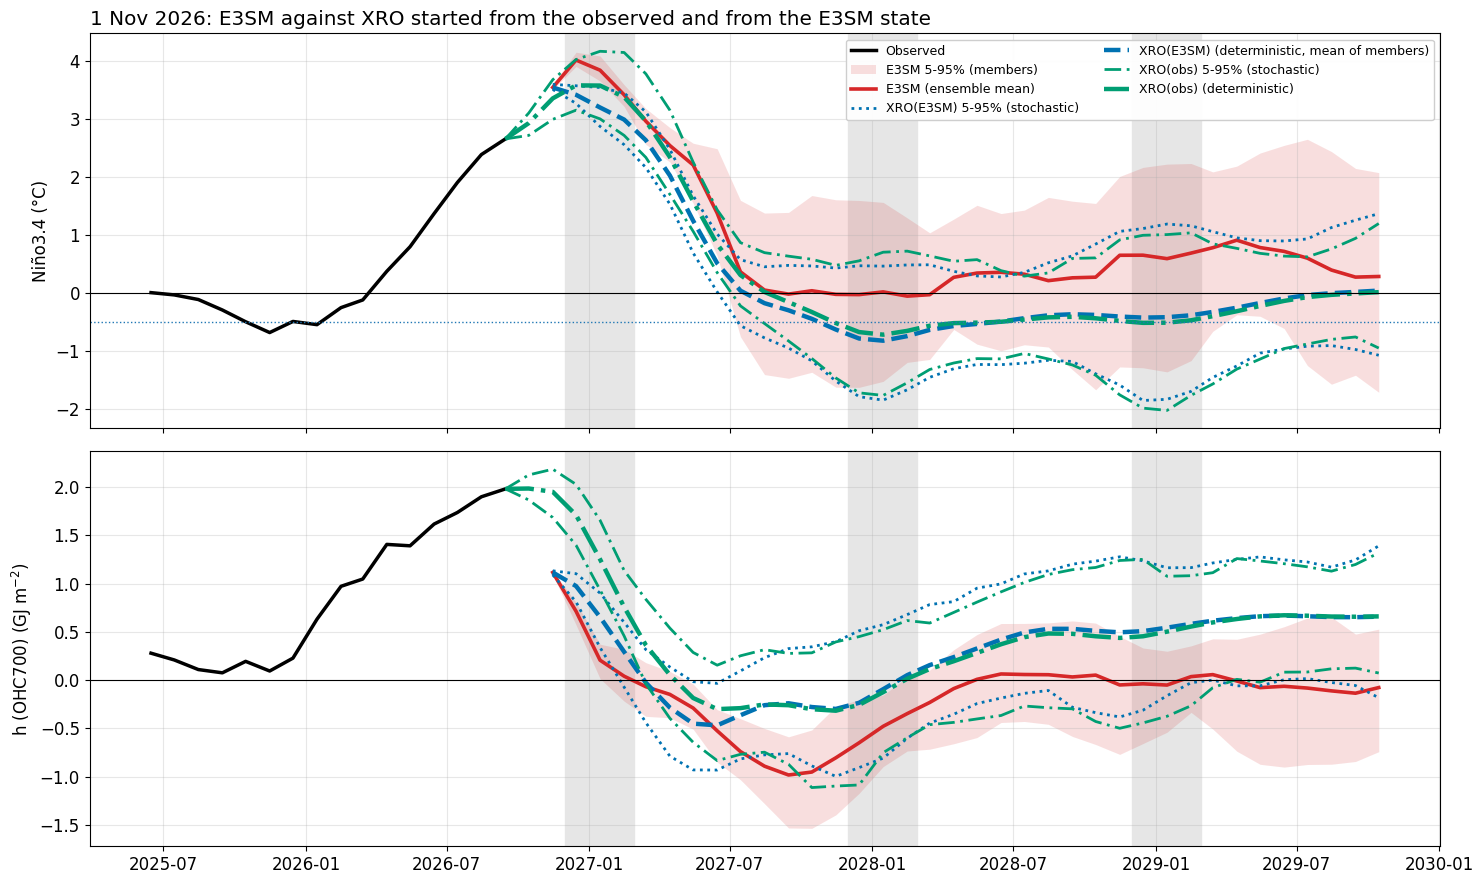

In [6]:
def series_plot(ax, var):
    o = X[var].sel(time=slice("2025-06", None)).dropna("time")
    ax.plot([pd.Timestamp(t.year, t.month, 15) for t in o["time"].values], o.values, color="k", lw=2.5, label="Observed")
    for name, det, ens in (("E3SM", E3SM[var].mean("member"), E3SM[var]),
                           ("XRO(E3SM)", E3SM_DET[var].mean("member"), E3SM_STO[var]),
                           ("XRO(obs)", OBS_DET[var], OBS_STO[var])):
        tt = [pd.Timestamp(t.year, t.month, 15) for t in (ens["time"].values)]
        lo_, hi_ = ens.quantile(LO / 100, "member"), ens.quantile(HI / 100, "member")
        if name == "E3SM":
            ax.fill_between(tt, lo_, hi_, color=COLORS[name], alpha=0.15, lw=0, label=f"E3SM {LO}-{HI}% (members)")
        else:
            for k, q in enumerate((lo_, hi_)):
                ax.plot(tt, q, color=COLORS[name], lw=2.0, ls=RANGE_STYLES[name],
                        label=f"{name} {LO}-{HI}% (stochastic)" if k == 0 else None)
        ax.plot(tt, det.values, color=COLORS[name], lw=3.2 if name.startswith("XRO") else 2.6, ls=STYLES[name],
                label=name + (" (deterministic, mean of members)" if name == "XRO(E3SM)" else " (deterministic)" if name == "XRO(obs)" else " (ensemble mean)"))
    for w in WINTERS.values():
        ax.axvspan(pd.Timestamp(w, 12, 1), pd.Timestamp(w + 1, 2, 28), color="0.9", zorder=0)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel(f"{xc.SHORT.get(var, var)} ({xc.UNITS[var]})")


fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
series_plot(axes[0], "Nino34")
axes[0].axhline(THRESHOLD, color="tab:blue", ls=":", lw=1)
series_plot(axes[1], "WWV")
axes[0].legend(fontsize=9, ncol=2, loc="upper right", framealpha=0.95)
axes[0].set_title("1 Nov 2026: E3SM against XRO started from the observed and from the E3SM state", loc="left")
fig.tight_layout()
save(fig, "xro", "obs_vs_e3sm_init", "plumes")
plt.show()

### 3. Phase plane: recharge *h* against Niño3.4

Deterministic paths (dots every 3 months, star at the start) from Nov 2026 (XRO(obs) from its initial month).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/09_xro_obs_vs_e3sm_init/figures/fig_xro_obs_vs_e3sm_init_phase_plane.png


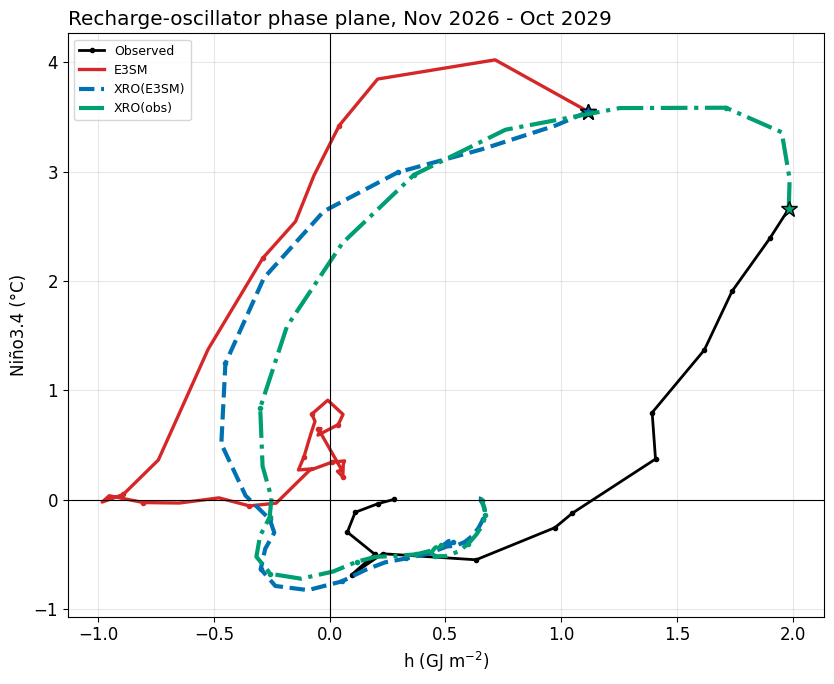

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 7))
o = X.sel(time=slice("2025-06", None)).dropna("time", subset=["Nino34", "WWV"])
ax.plot(o["WWV"], o["Nino34"], "k-o", ms=3, lw=2, label="Observed")
for name, ds in (("E3SM", E3SM.mean("member")), ("XRO(E3SM)", E3SM_DET.mean("member")), ("XRO(obs)", OBS_DET)):
    ax.plot(ds["WWV"], ds["Nino34"], color=COLORS[name], lw=3.0 if name.startswith("XRO") else 2.4, ls=STYLES[name], label=name)
    ax.plot(ds["WWV"][::3], ds["Nino34"][::3], "o", ms=3, color=COLORS[name])
    ax.plot(ds["WWV"][:1], ds["Nino34"][:1], "*", ms=12, color=COLORS[name], mec="k")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(f"h ({xc.UNITS['WWV']})")
ax.set_ylabel("Niño3.4 (°C)")
ax.legend(fontsize=9)
ax.set_title("Recharge-oscillator phase plane, Nov 2026 - Oct 2029", loc="left")
fig.tight_layout()
save(fig, "xro", "obs_vs_e3sm_init", "phase_plane")
plt.show()

### 4. DJF Niño3.4 and P(La Niña)

DJF means of the members (E3SM: 30 members; XRO(E3SM): 300 stochastic copies; XRO(obs): 100) and of the
deterministic runs; P(La Niña) = fraction ≤ −0.5 °C. XRO's raw stochastic spread is too narrow
(`enso/06_xro_validation`: about 60-80% coverage of a nominal 90% range), so XRO probabilities are sharper
than they should be.

In [8]:
def djf(da, w):
    keys = [(w, 12), (w + 1, 1), (w + 1, 2)]
    t = [(tt.year, tt.month) for tt in da["time"].values]
    if not all(k in t for k in keys):
        return None
    return da.isel(lead=[t.index(k) for k in keys]).mean("lead")


rows = []
for name, det, ens in (("E3SM", E3SM["Nino34"].mean("member"), E3SM["Nino34"]),
                       ("XRO(E3SM)", E3SM_DET["Nino34"].mean("member"), E3SM_STO["Nino34"]),
                       ("XRO(obs)", OBS_DET["Nino34"], OBS_STO["Nino34"])):
    row = {"forecast": name}
    ln = {}
    for lab, w in WINTERS.items():
        d, e = djf(det, w), djf(ens, w)
        row[f"DJF {lab} (det)"] = round(float(d), 2)
        row[f"DJF {lab} {LO}-{HI}%"] = f"{float(e.quantile(LO / 100)):.1f} to {float(e.quantile(HI / 100)):.1f}"
        ln[lab] = (e <= THRESHOLD).values
        row[f"P(LN {lab})"] = round(float(np.nanmean(ln[lab])), 2)
    row["P(LN 27/28 and 28/29)"] = round(float(np.nanmean(ln["2027/28"] & ln["2028/29"])), 2)
    rows.append(row)
djf_tab = pd.DataFrame(rows)
djf_tab.to_csv(DATA_DIR / "djf_nino34_la_nina.csv", index=False)
display(djf_tab.T)

# which part of the E3SM-minus-XRO(obs) difference is the initial state, which the dynamics
dec = []
for lab, w in WINTERS.items():
    e, xe, xo = (float(djf(s, w)) for s in (E3SM["Nino34"].mean("member"), E3SM_DET["Nino34"].mean("member"), OBS_DET["Nino34"]))
    dec.append({"winter": lab, "E3SM - XRO(obs)": round(e - xo, 2), "initial state: XRO(E3SM) - XRO(obs)": round(xe - xo, 2),
                "dynamics: E3SM - XRO(E3SM)": round(e - xe, 2)})
display(pd.DataFrame(dec))

,0,1,2
forecast,E3SM,XRO(E3SM),XRO(obs)
DJF 2026/27 (det),3.76,3.21,3.52
DJF 2026/27 5-95%,3.6 to 3.9,2.9 to 3.5,3.0 to 4.1
P(LN 2026/27),0.0,0.0,0.0
DJF 2027/28 (det),-0.02,-0.79,-0.69
DJF 2027/28 5-95%,-1.5 to 1.4,-1.8 to 0.4,-1.7 to 0.7
P(LN 2027/28),0.3,0.65,0.49
DJF 2028/29 (det),0.64,-0.41,-0.5
DJF 2028/29 5-95%,-1.2 to 2.2,-1.8 to 1.1,-1.9 to 1.0
P(LN 2028/29),0.17,0.49,0.48


,winter,E3SM - XRO(obs),initial state: XRO(E3SM) - XRO(obs),dynamics: E3SM - XRO(E3SM)
0,2026/27,0.25,-0.31,0.56
1,2027/28,0.66,-0.10,0.76
2,2028/29,1.15,0.09,1.05


### Findings

(XRO(obs) starts from Sep 2026, the latest fully observed month of HadISST 1.1 and EN4.2.2.)

**1. E3SM starts the forecast with much less recharge than the observations imply.** In Nov 2026 E3SM's
Niño3.4 (3.55 °C, all 30 members within 3.51-3.60) is close to what XRO projects from the observed September
state (3.36 °C; observed Sep: 2.66 °C), but its recharge *h* is 1.12 GJ m⁻² against 1.95 (observed Sep: 1.98),
i.e. about half. The Indian Ocean Dipole is also much weaker (0.46 against 1.18 °C) and the South Pacific
Meridional Mode warmer (+0.62 °C).

**2. That initial-state difference matters little for the outlook.** Run through the same XRO, the E3SM state
gives a slightly weaker 2026/27 peak (DJF 3.21 against 3.52 °C) and nearly the same La Niña in 2027/28 (−0.79
against −0.69 °C) and 2028/29 (−0.41 against −0.50 °C):

| DJF Niño3.4 (°C) | E3SM − XRO(obs) | initial state: XRO(E3SM) − XRO(obs) | dynamics: E3SM − XRO(E3SM) |
|---|---|---|---|
| 2026/27 | +0.25 | −0.31 | +0.56 |
| 2027/28 | +0.66 | −0.10 | +0.76 |
| 2028/29 | +1.15 | +0.09 | +1.05 |

**3. The gap between E3SM and an observation-based XRO forecast comes from E3SM's evolution, not its start.**
From the same initial states XRO cools to a La Niña in 2027/28 and stays near −0.5 °C into 2028/29, while
E3SM's ensemble mean levels off near 0 in 2027/28 and warms again to +0.6 °C in 2028/29. E3SM's *h* also stays
near zero after 2028, where XRO recharges to +0.5-0.7 GJ m⁻². This "dynamics" part includes the drift
correction: E3SM here is corrected with the fixed 1981-2010 drift, held in year 3, which `03`-`07` found leaves
year 2 about 1 °C too warm for a 2026 start. The trend-corrected drift (TrDC, `07`) moves E3SM most of the way
towards XRO.

**4. P(La Niña):**

| | 2027/28 | 2028/29 | both |
|---|---|---|---|
| E3SM, fixed 1981-2010 drift (as here) | 0.30 | 0.17 | 0.07 |
| E3SM, TrDC held at 2018, r = 1 (`07`) | 0.80 | 0.50 | 0.40 |
| XRO(E3SM) | 0.65 | 0.49 | 0.36 |
| XRO(obs) | 0.49 | 0.48 | 0.27 |

XRO's raw stochastic spread is too narrow (`enso/06_xro_validation`), so its probabilities are sharper than they
should be, but both XRO runs agree with the trend-corrected E3SM that a La Niña in 2027/28 is about as likely as
not or more, and that 2028/29 is close to even.

**5. Timing.** XRO(obs) peaks in Dec 2026, as E3SM does, and crosses zero around Aug-Sep 2027, as E3SM does; the
two then diverge (point 3).

**Updating.** HadISST 1.1 and EN4.2.2 for Oct 2026 are expected from the Met Office in early December; after
adding them to the archive, rerun this notebook and XRO(obs) starts from October (the month before the E3SM
start) by itself.